<a href="https://colab.research.google.com/github/RichardEager0803/Machine-Learning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment #4

#### Heart Disease Classification using Decision Trees & Support Vector Machines

Goals:

* Source the UCI Heart Disease dataset
* Inspect the dataset's structure
* Handle missing data
* Construct preprocessing pipelines using Scikit-Learn
* **Train a Support Vector Classifier (SVC) and a Decision Tree Classifier to predict the presence of heart disease.**



Imports:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

Task 1 - Loads the dataset into a Pandas DataFrame (called df).



In [2]:
pd.set_option('display.max_columns', None)

df = pd.read_csv('heart_disease.csv')


Task 2 - Uses inspection methods (head(), info(), and describe()) to analyze features.

In [3]:
print('\nHead Method: ')
print(df.head())

print('\nInfo Method: ')
print(df.info())

print('\nDescribe Method: ')
print(df.describe())


Head Method: 
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target     source  
0    3.0  0.0   6.0       0  cleveland  
1    2.0  3.0   3.0       1  cleveland  
2    2.0  2.0   7.0       1  cleveland  
3    3.0  0.0   3.0       0  cleveland  
4    1.0  0.0   3.0       0  cleveland  

Info Method: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64


Task 3 & 4 - Quantifies and handles any missing or implicit missing values across the columns, and implements a structured imputation strategy using Scikit-Learn's SimpleImputer.
Isolates numerical and categorical features, then applies appropriate scaling to numerical and encoding to categorical columns.

In [4]:
# Drops the non-informative source feature
df_clean = df.drop(columns=["source"])

print("\nMissing values before pipeline execution.")
print(df_clean.isnull().sum())

X = df_clean.drop(columns=["target"])
y = df_clean['target'].apply(lambda x: 1 if x > 0 else 0) # Binarizes the target if multi-class

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_cols = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categoric_cols = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

target_col = "target"

# Preprocessing steps for the numeric data (Impute missing and Scale)
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Preprocessing steps for categorical data (Impute missing and One-Hot Encode)
# handle_unknown='ignore' prevents errors if the test sets introduce unseen categories
categoric_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]
)

# Combines the transformers into a single column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categoric_transformer, categoric_cols)
    ]
)


Missing values before pipeline execution.
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalach      55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
dtype: int64


Task 5 - Instantiates and trains a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within the pipeline.
Evaluates performance using a confusion matrix, classification report, and ROC-AUC curve.

In [5]:
svc_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
    ]
)

svc_pipeline.fit(X_train, y_train)
y_pred_svc = svc_pipeline.predict(X_test)
y_prob_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print("\nSVC Classification Report")
print(classification_report(y_test, y_pred_svc))

print("\nSVC Confusion Matrix")
print(confusion_matrix(y_test, y_pred_svc))

print(f"SVC ROC-AUC Score: {roc_auc_score(y_test, y_prob_svc):.4f}")



SVC Classification Report
              precision    recall  f1-score   support

           0       0.89      0.76      0.82        82
           1       0.82      0.92      0.87       102

    accuracy                           0.85       184
   macro avg       0.86      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184


SVC Confusion Matrix
[[62 20]
 [ 8 94]]
SVC ROC-AUC Score: 0.9168


Task 6 - Instantiates and trains a Decision Tree Classifier (DecisionTreeClassifier) within the pipeline. Evaluates the performance using identical metrics to compare against the SVC model.

In [6]:
dt_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=4, random_state=42))
    ]
)

dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("\nDecision Tree Classification Report")
print(classification_report(y_test, y_pred_dt))

print("Decision Tree Confusion Matrix")
print(confusion_matrix(y_test, y_pred_dt))

print(f"Decision Tree ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt):.4f}")



Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.80      0.74      0.77        82
           1       0.81      0.85      0.83       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184

Decision Tree Confusion Matrix
[[61 21]
 [15 87]]
Decision Tree ROC-AUC Score: 0.8721


Task 7 - Hyperparameter tuning using GridSearchCV on the SVC pipeline.
Evaluates the performance using identical metrics to compare against the SVC model.

In [7]:
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters for SVC:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score for SVC:")
print(grid_search.best_score_)

best_svc = grid_search.best_estimator_
y_prob_best_svc = best_svc.predict_proba(X_test)[:, 1]
print(f"Optimized Test ROC-AUC Score: {roc_auc_score(y_test, y_prob_best_svc):.4f}")




Best Parameters for SVC:
{'classifier__C': 1, 'classifier__gamma': 0.1}

Best Cross-Validation Score for SVC:
0.8951390845428786
Optimized Test ROC-AUC Score: 0.9171


Task 8 - Generates a decision tree visualization (plot_tree) to interpret how the model separates patients with heart disease from healthy patients.

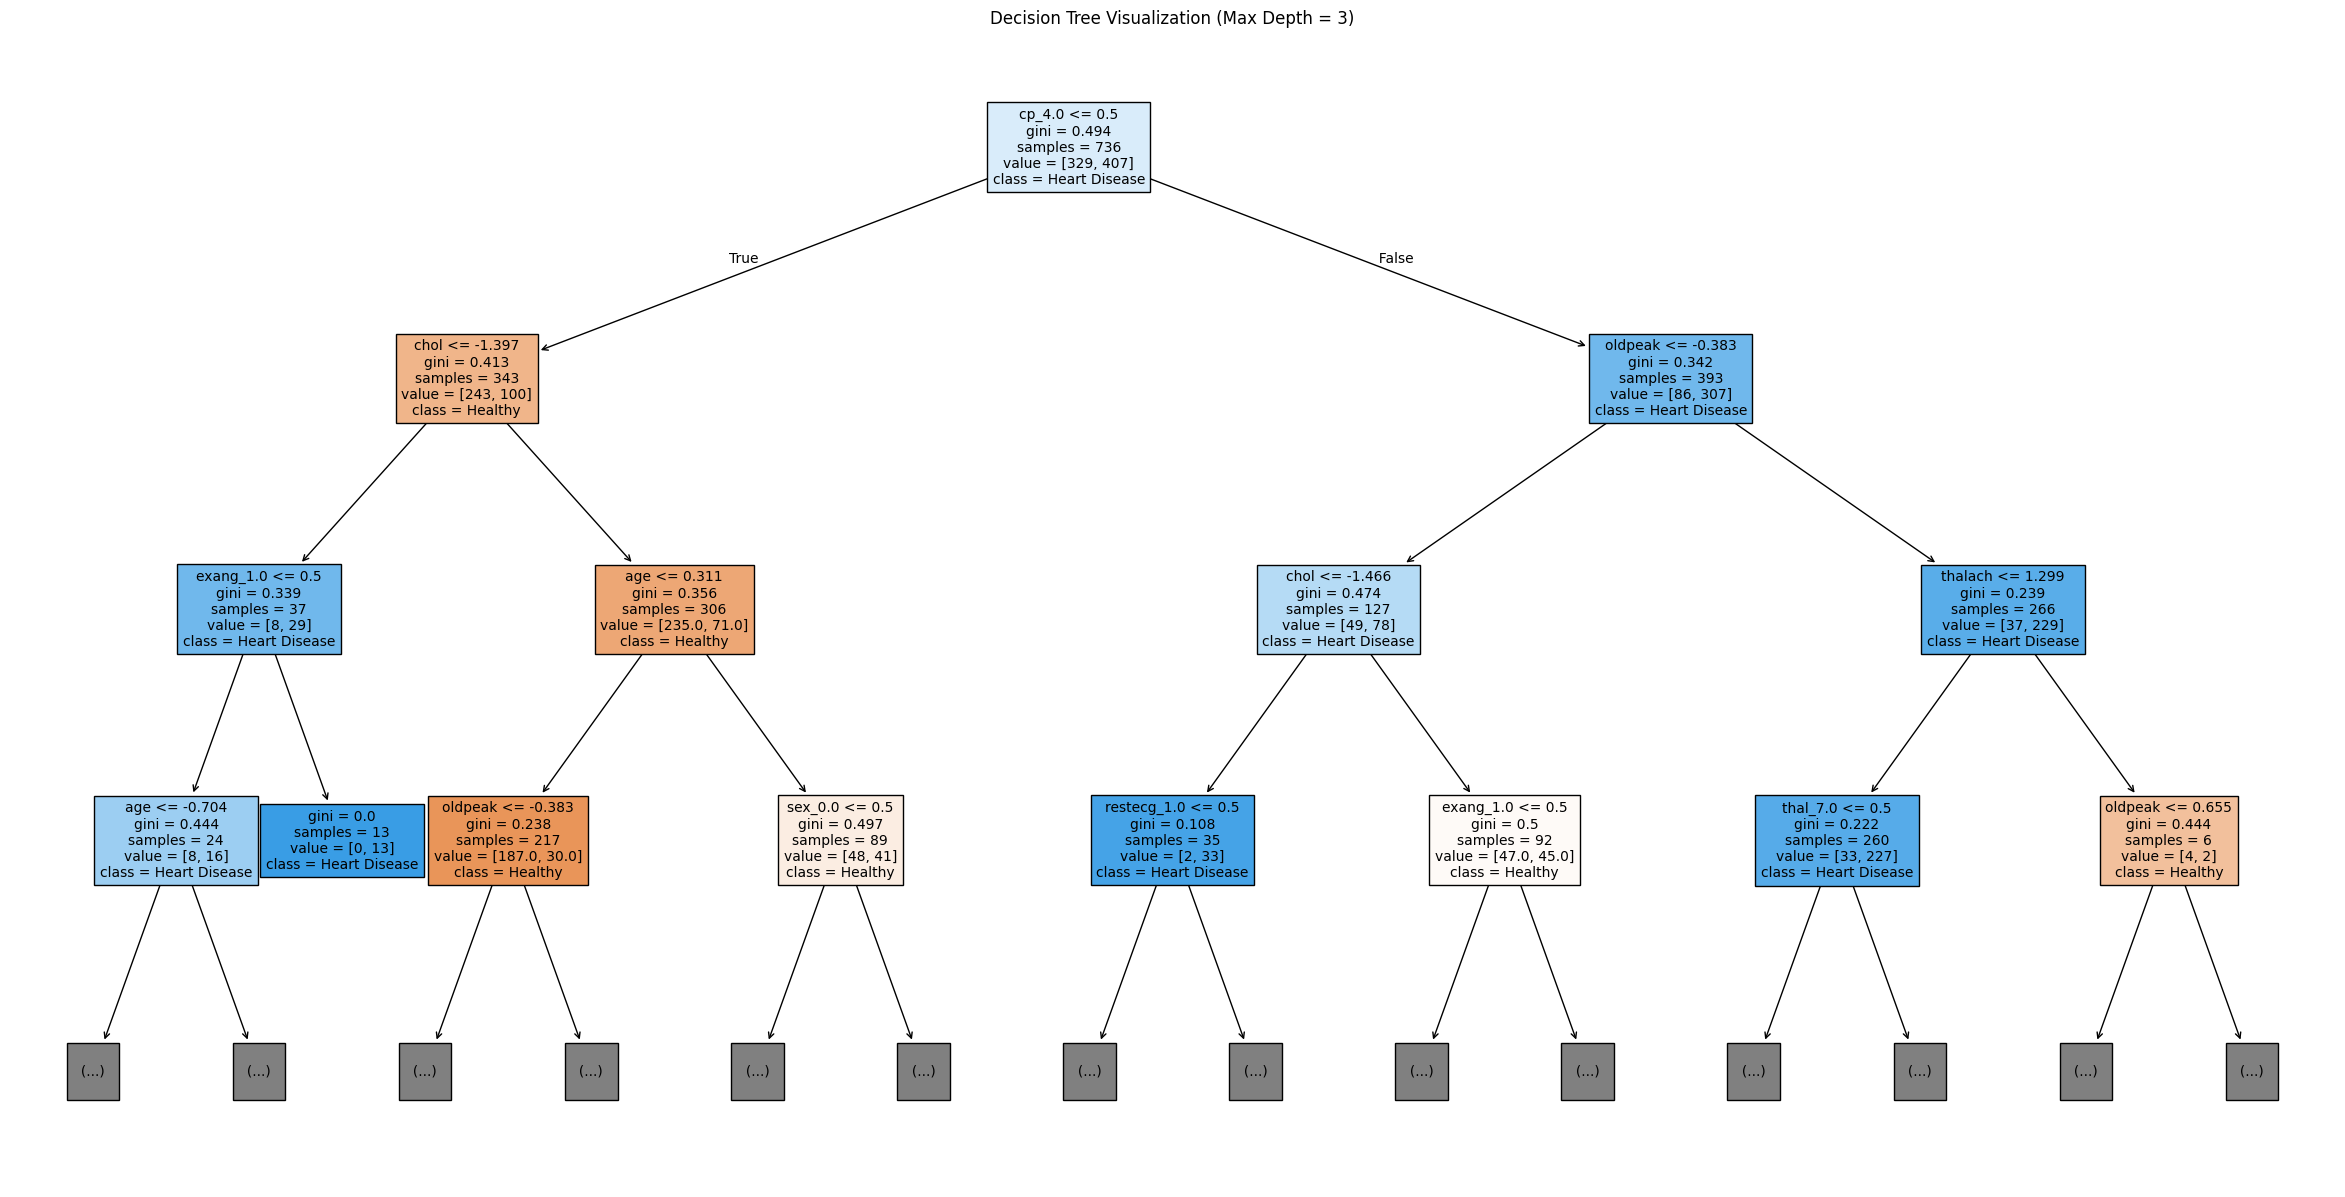

In [8]:
# Extracts feature names after OneHotEncoder transformation
cat_encoder = dt_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(categoric_cols).tolist()
all_feature_names = numeric_cols + encoded_cat_cols

plt.figure(figsize=(30, 15))
plot_tree(
    dt_pipeline.named_steps['classifier'],
    feature_names=all_feature_names,
    class_names=['Healthy', 'Heart Disease'],
    filled=True,
    max_depth=3, # Restricted depth for visual readability
    fontsize=10
)
plt.title("Decision Tree Visualization (Max Depth = 3)")
plt.show()

